# Identification
Please indicate your name and parcours (e.g.: IMA, DIGIT, BIM, DAC, ..., Erasmus)

Student 1: Daria Shtyka M1 MIND

Student 2: Charles Delemolle M1 MIND

# Practical work 1: introduction and image enhancement

- Quick start for Python (10 minutes!) : https://www.stavros.io/tutorials/python/
- Quick start for Numpy : https://numpy.org/devdocs/user/quickstart.html#
- For Matlab users: Numpy is very similar but with some important difference, see http://mathesaurus.sourceforge.net/matlab-numpy.html.
- Keep in mind that in Python, exception of variable of scalar type, all is reference and affectation is not a copy.


## Short introduction to image processing with Python

Help: use the function `help()` to get information on a Python objet.

Images are stored as arrays that is the default type of the `numpy` module. Defaut type of array elements is `float64` according to the IEEE754 norm. Special float values are defined: infinity (`inf`) and undefined (`nan`, *not a number*), and some numerical constants, such as $\pi$.



In [26]:
import numpy as np

print(np.inf,np.nan,np.pi)

print( 1., 1e10, -1.2e-3)

inf nan 3.141592653589793
1.0 10000000000.0 -0.0012


### Creating an array: several ways.

1. From a list of values (formally any Python iterable object). Elements of an array have the same **type**, determined by Numpy:

In [27]:
V = np.array([1,2,3])
M = np.array([[1,2,3],[4,5,6.]])
print ("V is of type",V.dtype)
print ("M is of type",M.dtype)

V is of type int64
M is of type float64


2. Without values: Numpy has constructors such as `empty()`, `zeros()`, `ones()`... Shape should be given (see below). Important: `empty()` does not initialize array elements.

In [28]:
I = np.zeros((3,4))
print(I)
J = np.empty((4,3))
print(J)

[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]
[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]


3. From a sequence, prefer `arange()` from numpy to `range()` from python.

In [29]:
print(np.arange(10))
print(np.arange(0,10,2))
print(np.arange(9,-1,-.5))

[0 1 2 3 4 5 6 7 8 9]
[0 2 4 6 8]
[ 9.   8.5  8.   7.5  7.   6.5  6.   5.5  5.   4.5  4.   3.5  3.   2.5
  2.   1.5  1.   0.5  0.  -0.5]


### Shape of an array

Shape decribes the number of elements for each dimension. A vector is of dimension 1, a matrix is of dimension 2. Superior dimensions are possible. Shape is not size that is the number of elements of an array. Type of shape is always a tuple of integers. With previous example:

In [30]:
print(I.shape, I.size)
print(J.shape, J.size)
print(V.shape, V.size)

(3, 4) 12
(4, 3) 12
(3,) 3


An important function/method is `reshape()` to change the shape of an array. Typical usage of `reshape()` is to transform a vector into a matrix or reciprocally.

In [31]:
K = np.arange(12).reshape((3,4))
print(K)
print(np.reshape(K,(12)))
print(K.reshape((2,2,3)))

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
[ 0  1  2  3  4  5  6  7  8  9 10 11]
[[[ 0  1  2]
  [ 3  4  5]]

 [[ 6  7  8]
  [ 9 10 11]]]


### Elements of an array

Access element by indices: two syntaxe are possible, the first given in the example is prefered. Negative index is possible with the same meanning of Python list.

In [32]:
I = np.arange(12).reshape((3,4))
print(I)
print(I[1,2])
print(I[0][0])
print(I[-1,0])

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
6
0
8


Access by group of indices using the operator `:` allows to extract subarray. General syntaxe is `start:end:step` and it is very powerfull:

In [33]:
print('extract the first line')
print(I[0,:])
print(I[0,0:])
print(I[0,::])
print(I[0,::1])
print('extract center of the array')
print(I[1:3,1:3])

print('extract elements with even indices')
print(I[::2,::2])

print('print the horizontal mirror of an array')
print(I[:,::-1])

extract the first line
[0 1 2 3]
[0 1 2 3]
[0 1 2 3]
[0 1 2 3]
extract center of the array
[[ 5  6]
 [ 9 10]]
extract elements with even indices
[[ 0  2]
 [ 8 10]]
print the horizontal mirror of an array
[[ 3  2  1  0]
 [ 7  6  5  4]
 [11 10  9  8]]


### Array arithmetic

Operators and functions can be applied to arrays. Mostly, operations are element-wise (i.e. applied element by element). The consequence is arrays should have the same shape. One operand can also be scalar in most of time.

In [34]:
A = np.arange(12).reshape((3,4))
B = 2 * A + 1
C = A + B
D = np.cos(2*np.pi*A/12)
print(A)
print (D)
print (D**2)
print (D>0)

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
[[ 1.00000000e+00  8.66025404e-01  5.00000000e-01  6.12323400e-17]
 [-5.00000000e-01 -8.66025404e-01 -1.00000000e+00 -8.66025404e-01]
 [-5.00000000e-01 -1.83697020e-16  5.00000000e-01  8.66025404e-01]]
[[1.00000000e+00 7.50000000e-01 2.50000000e-01 3.74939946e-33]
 [2.50000000e-01 7.50000000e-01 1.00000000e+00 7.50000000e-01]
 [2.50000000e-01 3.37445951e-32 2.50000000e-01 7.50000000e-01]]
[[ True  True  True  True]
 [False False False False]
 [False False  True  True]]


Array may be viewed as matrix, we can make some linear algebraic manipulation. For example, `np.matmul()` is the matrix multiplication. It can be used to build matrix from vector. An example, using the transpose operator `T`.

In [35]:
L = np.arange(1,6).reshape((1,5))
C = L.T
C = L.T.copy()

print("A 5*5 matrix:")
print(np.matmul(C,L))

print("A dot product, but result is a matrix:")
print(np.matmul(L,C))
print(np.matmul(L,C)[0,0])

print("dot() is prefered with vectors:")
V = np.arange(1,6)
print(V.dot(V))
print(np.dot(V,V))

A 5*5 matrix:
[[ 1  2  3  4  5]
 [ 2  4  6  8 10]
 [ 3  6  9 12 15]
 [ 4  8 12 16 20]
 [ 5 10 15 20 25]]
A dot product, but result is a matrix:
[[55]]
55
dot() is prefered with vectors:
55
55


### Images

We make use of PIL module (https://pillow.readthedocs.io/en/stable/reference/Image.html) to load and write an image and easily converted to Numpy array. Be careful: array type depends on image.

In [36]:
from PIL import Image

myimage = np.array(Image.open('img/moon.png'))

Image.fromarray(myimage).save('img/pout.jpg')

Array can be displayed as an image using Matplotlib module. Here a short example:

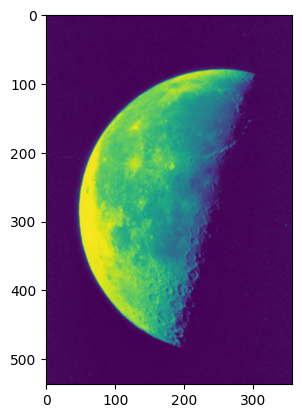

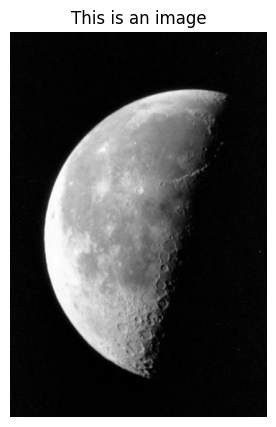

In [37]:
import matplotlib.pyplot as plt

plt.imshow(myimage)
plt.show()

w,h=400,400
plt.figure(figsize=(w/80,h/80))
plt.gray()
plt.title('This is an image')
plt.axis('off')
plt.imshow(myimage)
plt.show()

See also:
- https://matplotlib.org/3.1.1/tutorials/introductory/images.html
- https://matplotlib.org/stable/gallery/images_contours_and_fields/image_demo.html

## Exercise 1
In this exercise, we work with image `img/moon.png`. If possible give two solutions: one with loops (for, while, ...) and one without loops using Numpy arithmetic avoiding ad-hoc Numpy functions such as `np.where()`.

1. Write and test a function `openImage()` getting an image filename as argument and returning the array of pixel values.

array([[ 1,  3,  7, ...,  8, 16,  8],
       [ 3,  7,  3, ...,  4, 11, 12],
       [ 6,  4,  6, ...,  7,  2,  3],
       ...,
       [ 4,  8,  8, ...,  6,  4,  8],
       [ 4,  8,  8, ...,  4,  6,  6],
       [ 2,  3,  3, ...,  6,  9,  9]], dtype=uint8)
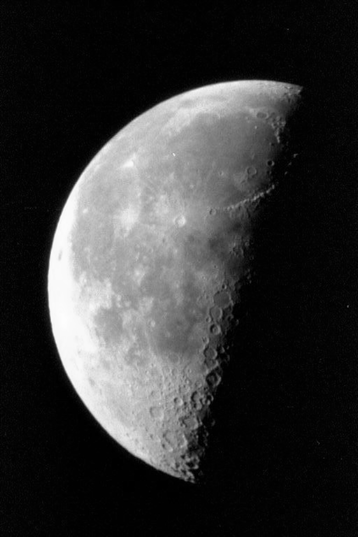

In [38]:
from PIL import Image
import numpy as np

def openImage(fname):
    myimage = np.array(Image.open(fname))
    return myimage

openImage('img/moon.png')

2. Write and test a function `countPixels()` getting an array and an integer `k` as arguments and returning the number of pixels having the value `k`.

In [39]:
def countPixels(I,k):
    cpt = 0
    for i in range(I.shape[0]):
        for j in range(I.shape[1]):
            if I[i][j] == k:
                cpt += 1
    return cpt

def countPixel1(I,k):
    cpt = 0
    return np.where(I==k)[0].size

print(countPixels(I, 5))
print(countPixel1(I,5))

1
1


3. Write and test a function `replacePixels()` getting an array and two intergers and replacing pixels having `k1`value to `k2` value and returning the new array. Be aware to not modify `I`.

In [40]:
def replacePixels(I,k1,k2):
    new_array = np.copy(I)
    for i in range(I.shape[0]):
        for j in range(I.shape[1]):
            if new_array[i][j] == k1:
                new_array[i][j] = k2
    return new_array

def replacePixels1(I,k1,k2):
    new_array = np.copy(I)
    new_array[new_array == k1] = k2
    return new_array

print(I)
print(replacePixels(I,0,100))
print(replacePixels1(I,0,100))

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
[[100   1   2   3]
 [  4   5   6   7]
 [  8   9  10  11]]
[[100   1   2   3]
 [  4   5   6   7]
 [  8   9  10  11]]


4. Write and test a function `normalizeImage()` getting an array and two integers `k1` and `k2` and returning an array with elements normalized to the interval $[k_1,k_2]$.

In [41]:
def normalizeImage(I,k1,k2):
    new_array= np.copy(I).astype(float)
    i1 = I.min()
    i2 = I.max()
    for i in range(I.shape[0]):
        for j in range(I.shape[1]):
            new_array[i][j] = ((I[i][j]-i1) / (i2-i1)) * (k2-k1) + k1
    return new_array

def normalizeImage1(I,k1,k2):
    return k1 + (I - I.min()) * (k2 - k1) / (I.max() - I.min())

print(normalizeImage(I, 5, 7))
print(normalizeImage1(I, 5, 7))

[[5.         5.18181818 5.36363636 5.54545455]
 [5.72727273 5.90909091 6.09090909 6.27272727]
 [6.45454545 6.63636364 6.81818182 7.        ]]
[[5.         5.18181818 5.36363636 5.54545455]
 [5.72727273 5.90909091 6.09090909 6.27272727]
 [6.45454545 6.63636364 6.81818182 7.        ]]


5. Write and test a function `inverteImage()` getting an array and returning and arry having inverted pixel values (i.e. the transform $k \mapsto 255-k$

In [42]:
def inverteImage(I):
    new_array = np.copy(I)
    for i in range(I.shape[0]):
        for j in range(I.shape[1]):
            new_array[i][j] = 255 - new_array[i][j]
    return new_array

def inverteImage1(I):
    new_array = np.copy(I)
    new_array = 255 - new_array
    return new_array

print(I)
print(inverteImage(I))
print(inverteImage1(I))

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
[[255 254 253 252]
 [251 250 249 248]
 [247 246 245 244]]
[[255 254 253 252]
 [251 250 249 248]
 [247 246 245 244]]


6. Write and test a function `computeHistogram()` getting an array and returning its histogram. Type of histogram can be an array or a list. It is forbidden to use an histogram method from a Python module. Is it possible to compute the histogram without explicitely visiting array pixels?

In [53]:
def computeHistogram(I):
    dico = {}
    for i in range(I.shape[0]):
        for j in range(I.shape[1]):
            pixel = I[i, j].item()

            dico[pixel] = dico.get(pixel, 0) + 1

    histogram = [[pixel, occur] for pixel, occur in dico.items()]
    return histogram

print(computeHistogram(I))

[[0, 1], [1, 1], [2, 1], [3, 1], [4, 1], [5, 1], [6, 1], [7, 1], [8, 1], [9, 1], [10, 1], [11, 1]]


7. Write and test a function `thresholdImage()` getting an array `I` and an integer `s` and returning an array having elements set to 0 if corresponding element of `I` is lower than `s` or 255 otherwise.

In [44]:
def thresholdImage(I,s):
    new_array = np.copy(I)
    for i in range(I.shape[0]):
        for j in range(I.shape[1]):
           if I[i][j] < s:
                 new_array[i][j] = 0
           else:
            new_array[i][j] = 255
    return new_array

print(thresholdImage(I, 3))

[[  0   0   0 255]
 [255 255 255 255]
 [255 255 255 255]]


8. Using previous functions, give a series of instructions to read then to display an image, plot the histogram (one can use `plot()` or `bar()` from `matplotlib.pyplot` module), inverse the image and display it, plot its histogram.

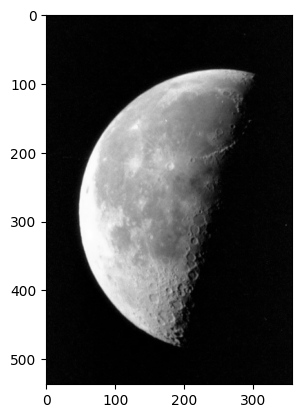

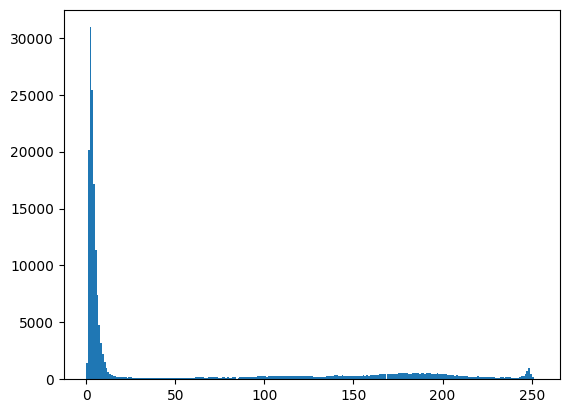

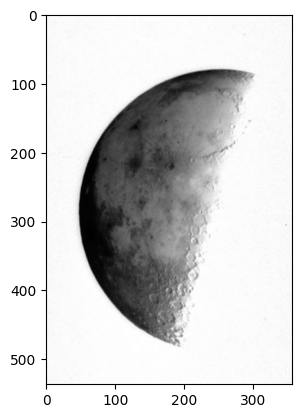

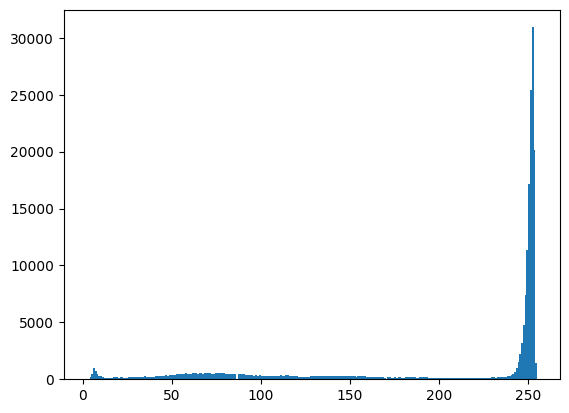

In [45]:
import matplotlib.pyplot as plt

def test(fname):
    I = openImage(fname)
    plt.imshow(I)
    plt.show()
    plt.hist(I.reshape(-1), bins=256)
    plt.show()
    I = inverteImage(I)
    plt.imshow(I)
    plt.show()
    plt.hist(I.reshape(-1), bins=256)
    plt.show()

test('img/moon.png')

9. Give a series of instructions to read and display an image, plot the histogram, normalize the image to the interval $[10,50]$, compute the new histogram, display the image and the histogram. Remark: `imshow()` normalizes image. To avoid this and see the effect of the normalization, use `imshow()` with parameters `vmin=0,vmax=255`. Comment the results.

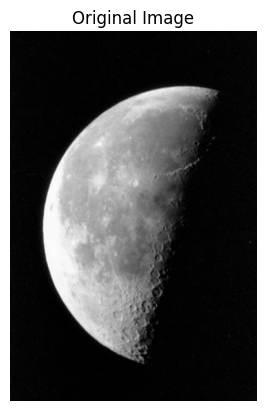

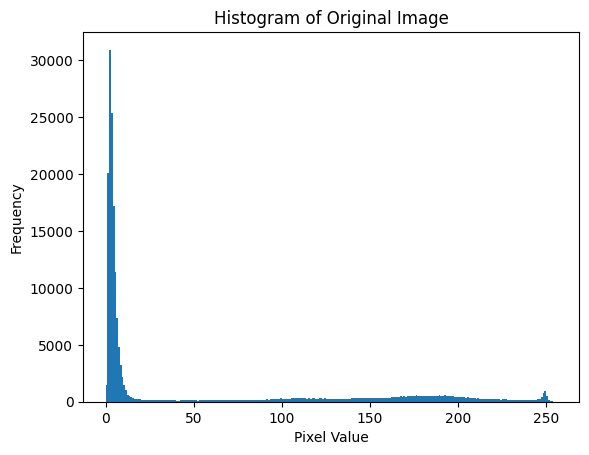

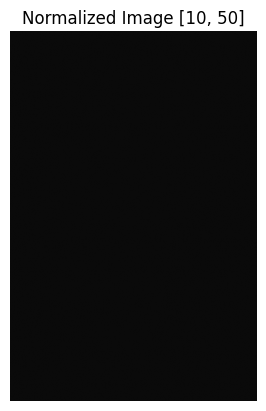

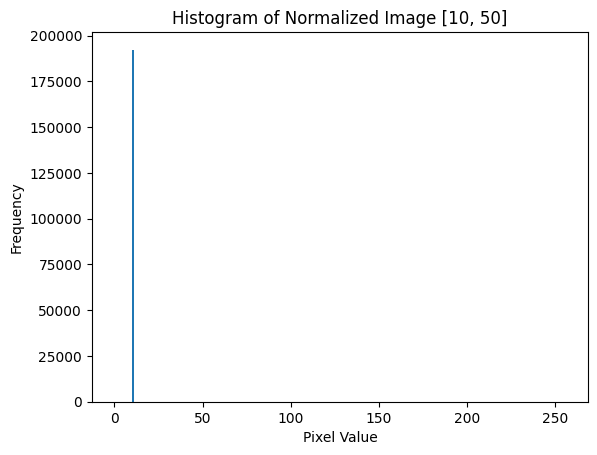

In [46]:
import matplotlib.pyplot as plt

def answer_question_9(fname):
    I = openImage(fname)

    plt.imshow(I, vmin=0, vmax=255)
    plt.title('Original Image')
    plt.axis('off')
    plt.show()

    plt.hist(I.reshape(-1), bins=256, range=[0, 256])
    plt.title('Histogram of Original Image')
    plt.xlabel('Pixel Value')
    plt.ylabel('Frequency')
    plt.show()

    I_normalized = normalizeImage1(I, 10, 50)

    plt.imshow(I_normalized, vmin=0, vmax=255)
    plt.title('Normalized Image [10, 50]')
    plt.axis('off')
    plt.show()

    plt.hist(I_normalized.reshape(-1), bins=256, range=[0, 256])
    plt.title('Histogram of Normalized Image [10, 50]')
    plt.xlabel('Pixel Value')
    plt.ylabel('Frequency')
    plt.show()

answer_question_9('img/moon.png')

10. Same question than 9. remplacing the normalization by a thresholding with parameter $s=127$.

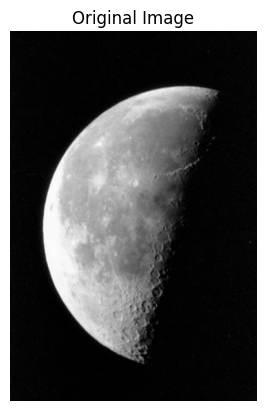

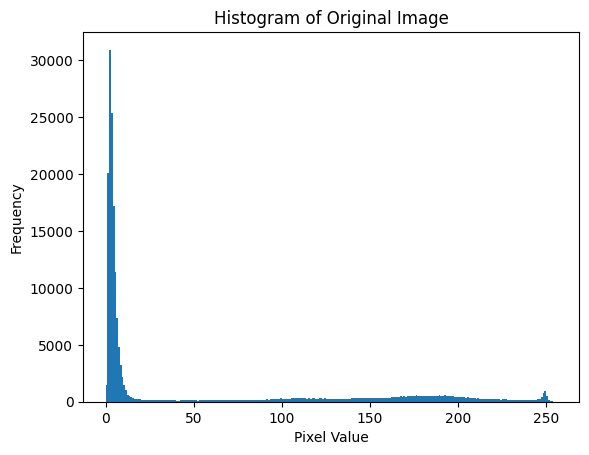

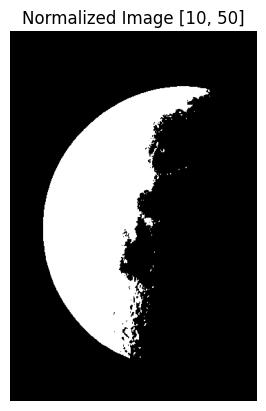

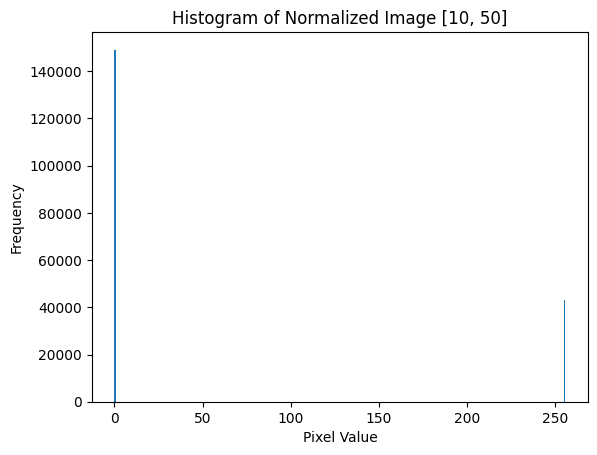

In [47]:
import matplotlib.pyplot as plt

def answer_question_9(fname):
    I = openImage(fname)

    plt.imshow(I, vmin=0, vmax=255)
    plt.title('Original Image')
    plt.axis('off')
    plt.show()

    plt.hist(I.reshape(-1), bins=256, range=[0, 256])
    plt.title('Histogram of Original Image')
    plt.xlabel('Pixel Value')
    plt.ylabel('Frequency')
    plt.show()

    I_normalized = thresholdImage(I, 127)

    plt.imshow(I_normalized, vmin=0, vmax=255)
    plt.title('Normalized Image [10, 50]')
    plt.axis('off')
    plt.show()

    plt.hist(I_normalized.reshape(-1), bins=256, range=[0, 256])
    plt.title('Histogram of Normalized Image [10, 50]')
    plt.xlabel('Pixel Value')
    plt.ylabel('Frequency')
    plt.show()

answer_question_9('img/moon.png')

## Exercise 2 - generate images

1. Create the array `I` 4 by 4 corresponding to the following image: <div> <img src="attachment:synthese.png" width="150"/> </div> Black pixels have value 0, white pixels value 255, and grey pixels value 127. Display the image using `imshow()` and plot the histogram.

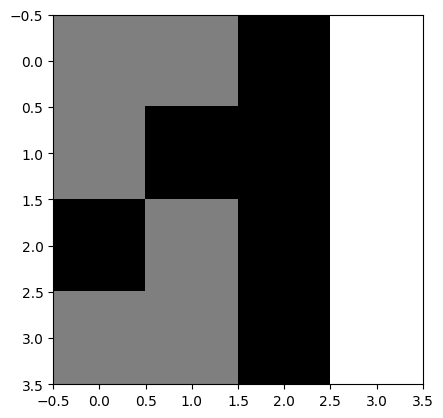

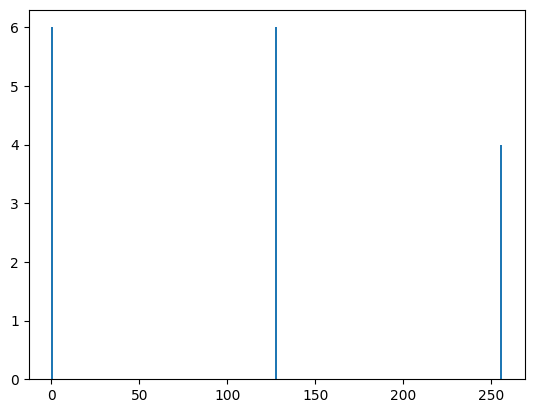

In [48]:
img = np.array([
    [127, 127, 0, 255],
    [127, 0, 0, 255],
    [0, 127, 0, 255],
    [127, 127, 0, 255]
])

plt.imshow(img, cmap='gray')
plt.show()

plt.hist(img.ravel(), bins=256, range=(0, 256))
plt.show()

2. We want to generate an image having random values. Functions `rand()` and `randn()` from  `numpy.random` module generate an array of given shapes with random values following a uniform distribution on $[0,1[$ and a normal distribution respectively. Create an array of shape 512 by 512 having **integer** elements following a uniform distribution in the set $\{0,1,\cdots,255\}$. We also want to create an array following a Gaussian distribution with a mean of 128 and a standard deviation of 16 and with **integer** values.  Display the images and their histograms. Discuss the results.

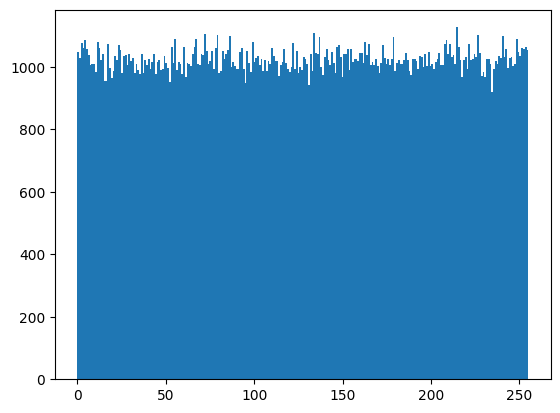

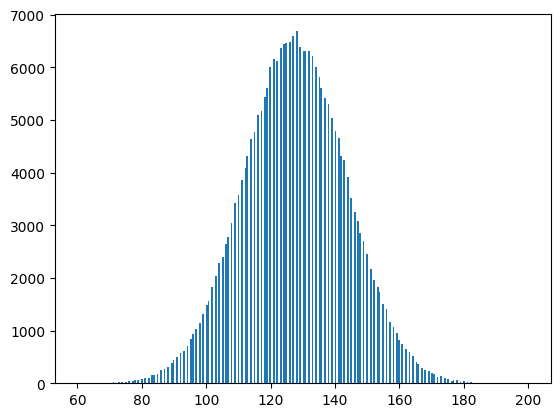

In [49]:
img = np.empty((512, 512), dtype=int)
for i in range(512):
  for j in range(512):
    img[i][j] = np.random.randint(0, 256)

plt.hist(img.ravel(), bins=256)
plt.show()

array = np.random.normal(loc=128, scale=16, size=(512, 512)).astype(int)

## Exercise 3: image manipulation
In this exercise, we work with image `img/pout.png`.

1. Read and display this image

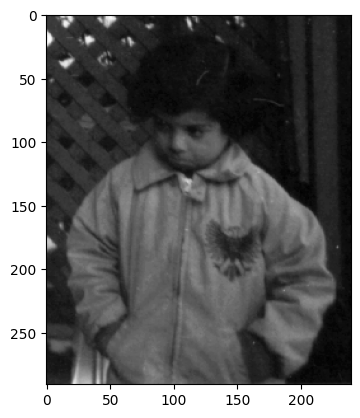

In [50]:
pout = openImage('img/pout.png')
plt.imshow(pout)
plt.show()

2. Examine the histogram. Determine the extrema of the image. What can you say about the quality of this image?

Max value:  224
(291, 240)


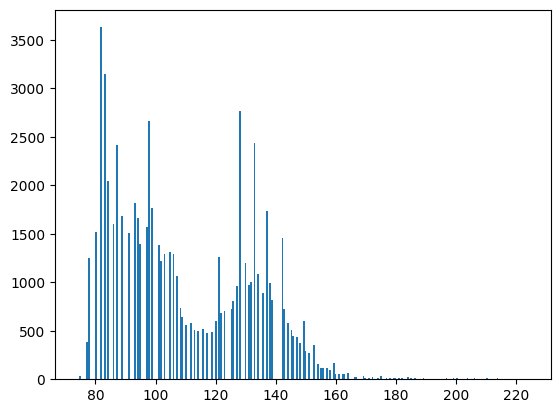

In [51]:
plt.hist(pout.reshape(-1), bins=256)
print("Max value: ", pout.max())
print(pout.shape)
plt.show()

3. Using functions from Exercice 1, write the function `histogramEqualization()` getting one image, its histogram,  applying an histogram equalization and returning the new image. Test this function on `pout.png` and discuss the result.

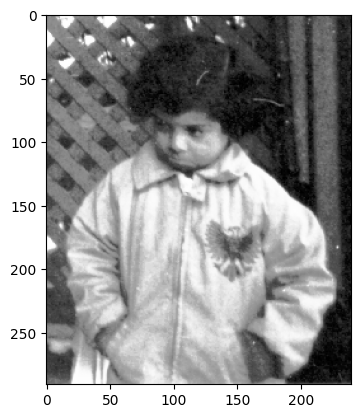

In [58]:
def histogramEqualization(I, h):
    full_hist = np.zeros(256, dtype=int)
    for pixel_value, count in h:
        if 0 <= pixel_value <= 255:
            full_hist[pixel_value] = count

    cdf = full_hist.cumsum()

    cdf_min_indices = np.where(cdf > 0)
    if cdf_min_indices[0].size > 0:
        cdf_min = cdf[cdf_min_indices].min()
    else:
        cdf_min = 0

    total_pixels = I.size

    if (total_pixels - cdf_min) == 0:
        normalized_cdf = np.zeros_like(cdf, dtype='uint8')
    else:
        normalized_cdf = ((cdf - cdf_min) * 255 / (total_pixels - cdf_min)).astype('uint8')

    equalized_image = normalized_cdf[I]

    return equalized_image

equalized_pout = histogramEqualization(pout, computeHistogram(pout))
plt.imshow(equalized_pout)
plt.show()

# We can see that the resulting image is brighter than the original, thanks to the use of the whole dynamic of grey levels